# 02 – Building the modelling dataset (leakage-free features)

**One row = one player at one valuation date *t*.**

- **Target:** `y = log(market value ≈ 12 months later)`. We use the player's valuation closest to *t* + 365 days, and it must fall within ± 60 days. Rows with no such valuation are dropped.
- **Features:** only records dated **on or before *t*** are used. The feature code is in `src/features.py`, so notebooks 03 and 04 reuse exactly the same logic.
- **Star players stay in.** Nothing is removed for being expensive.

Sections:
0. Check that the Parquet files match the original CSVs
1. Columns we do **not** use, and the evidence for each
2. Build features and target
3. League coverage: which leagues have match data for the whole period
4. Time-based split (train / validation / test)
5. Feature list
6. Leakage checks
7. Save the dataset

In [1]:
import sys, zipfile, warnings, time
from pathlib import Path
warnings.filterwarnings("ignore", message="IProgress not found")

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
from src.config import (RAW_ZIP, PROCESSED, RESULTS, SEED, TRAIN_END, VAL_END,
                        set_seed, savefig, apply_plot_style, PALETTE)
from src.features import (load_tables, build_features, add_target, FEATURES, CATEGORICAL,
                          FEATURE_INFO)

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import pyarrow.csv as pacsv, pyarrow.parquet as pq

set_seed(SEED)
apply_plot_style()
pd.set_option("display.width", 160, "display.max_columns", 30)

## 0. Do the Parquet files match the original CSVs?

Each CSV is read again with a different parser (PyArrow) and its row count is compared with the Parquet file.

In [2]:
TABLES = ["players", "player_valuations", "appearances", "transfers", "clubs",
          "competitions", "games", "club_games", "countries", "national_teams"]
rows = []
with zipfile.ZipFile(RAW_ZIP) as zf:
    for t in TABLES:
        with zf.open(f"{t}.csv") as fh:
            n_csv = pacsv.read_csv(fh).num_rows
        n_pq = pq.ParquetFile(PROCESSED / f"{t}.parquet").metadata.num_rows
        rows.append({"table": t, "csv_rows": n_csv, "parquet_rows": n_pq, "match": n_csv == n_pq})
rowcheck = pd.DataFrame(rows)
assert rowcheck["match"].all()
rowcheck

,table,csv_rows,parquet_rows,match
0,players,50149,50149,True
1,player_valuations,656301,656301,True
2,appearances,1894350,1894350,True
3,transfers,175165,175165,True
4,clubs,796,796,True
5,competitions,65,65,True
6,games,88958,88958,True
7,club_games,177916,177916,True
8,countries,124,124,True
9,national_teams,124,124,True


## 1. Columns we do **not** use, and why

`players.csv` stores some columns as they were on the 2026 scrape date. They describe the player *today*, so we drop them:
`contract_expiration_date`, `international_caps` (see notebook 01), `current_club_*`, `market_value_in_eur`, `highest_market_value_in_eur`.

**`player_valuations.csv` has the same problem, which was not obvious.** Its `current_club_id` and league columns should be the club at *t*. Below we test this.
- If the player has an earlier transfer in `transfers.csv`, the club equals that transfer's destination, which is correct.
- If there is **no** earlier transfer, the column holds the player's **2026 club** (example: Miroslav Klose's 2004 valuation, when he played for Werder Bremen, shows Lazio).

In [3]:
raw_v = pd.read_parquet(PROCESSED / "player_valuations.parquet").sort_values("date")
raw_t = pd.read_parquet(PROCESSED / "transfers.parquet").dropna(subset=["transfer_date"]).sort_values("transfer_date")
today = pd.read_parquet(PROCESSED / "players.parquet", columns=["player_id", "current_club_id"])
raw_t["transfer_date"] = raw_t["transfer_date"].astype(raw_v["date"].dtype)

chk = pd.merge_asof(raw_v, raw_t[["player_id", "transfer_date", "to_club_id"]],
                    left_on="date", right_on="transfer_date", by="player_id")
chk = chk.merge(today.rename(columns={"current_club_id": "club_2026"}), on="player_id")
chk = chk[chk["date"] >= "2014-07-01"]
has_tr = chk["to_club_id"].notna()
evidence = pd.DataFrame({
    "rows (t ≥ 2014-07)": [has_tr.sum(), (~has_tr).sum()],
    "valuation club = last transfer's club (%)": [
        100 * (chk.loc[has_tr, "current_club_id"] == chk.loc[has_tr, "to_club_id"]).mean(), np.nan],
    "valuation club = 2026 club (%)": [
        100 * (chk.loc[has_tr, "current_club_id"] == chk.loc[has_tr, "club_2026"]).mean(),
        100 * (chk.loc[~has_tr, "current_club_id"] == chk.loc[~has_tr, "club_2026"]).mean()],
}, index=["has an earlier transfer", "no earlier transfer"]).round(1)
evidence.to_csv(RESULTS / "table02_valuation_club_leakage.csv")
display(evidence)
print("Klose (id 10) valuations:")
display(raw_v[raw_v.player_id == 10][["date", "market_value_in_eur", "current_club_id"]].head(4))
del raw_v, raw_t, chk

,rows (t ≥ 2014-07),valuation club = last transfer's club (%),valuation club = 2026 club (%)
has an earlier transfer,328833,100.0,32.7
no earlier transfer,207325,NaN,100.0


Klose (id 10) valuations:


,date,market_value_in_eur,current_club_id
4,2004-10-04,7000000,398
2328,2005-01-07,9000000,398
3126,2005-05-05,12000000,398
4020,2005-09-30,15000000,398


**So "club at *t*" is rebuilt from leak-free sources** (`src/features.py → club_at_t`). We take whichever of these is more recent:
- the destination club of the player's **last transfer on/before *t***, or
- the club in the player's **last match on/before *t*** (within 365 days).

**League at *t*** is the domestic league of that club's most recent league match on/before *t* (within 150 days).
- `OTHER` = the club is known but did not play in a league covered by the data at that time (e.g. a second division).
- `UNKNOWN` = no transfer or match tells us the club.

**International caps before *t*:** `appearances` contains only ~3,000 national-team matches, and `games` has no player-level data for them. A leak-free caps feature is therefore **not feasible**, so we skip it.

In [4]:
apps_nt = (pd.read_parquet(PROCESSED / "appearances.parquet", columns=["competition_id"])
             .merge(pd.read_parquet(PROCESSED / "competitions.parquet", columns=["competition_id", "type"]),
                    on="competition_id", how="left"))
print("National-team appearances in the data:", int((apps_nt["type"] == "national_team_competition").sum()))
del apps_nt

National-team appearances in the data: 3027


## 2. Build features and target

`build_features` computes all 50 features for **every** valuation (656k rows), and `add_target` attaches the 12-month-ahead value.

**Start date: 1 July 2014.**

> *For the paper:* Player-level match data (appearances) in the source dataset start in July 2012. The longest performance look-back window covers the 730 days before *t* (minutes and goal contributions in the previous season). We therefore use valuation dates from 1 July 2014 onward, so that every look-back window is fully covered by match data. Earlier valuations are used only as history (e.g. past values, maximum value so far), never as rows.

In [5]:
t0 = time.time()
data = load_tables()
F = build_features(data)
F = add_target(F, data["vals"])
print(f"built in {time.time() - t0:.0f} s  |  {F.shape[0]:,} rows × {F.shape[1]} columns")

START = "2014-07-01"
D = F[(F["t"] >= START) & F["y"].notna()].copy()
D["target_gap_days"] = (D["target_date"] - D["t"]).dt.days
print(f"rows with t ≥ {START} and a 12-month target: {len(D):,}")
D["target_gap_days"].describe().round(1).to_frame().T

base rows: 656,300


club & league at t done


squad snapshots: 260 month-ends


all feature groups done
built in 8 s  |  656,300 rows × 62 columns


rows with t ≥ 2014-07-01 and a 12-month target: 357,730


,count,mean,std,min,25%,50%,75%,max
target_gap_days,357730.0,362.6,25.8,305.0,348.0,364.0,376.0,425.0


## 3. League coverage

Match data (`games`, `appearances`) does **not** cover all leagues over the full period:
- **14 European leagues** have matches from 2012 to 2026.
- **17 leagues** (e.g. Brazil, MLS, Saudi Arabia, Austria, Poland) appear only from **2024/25**.

Before 2024, a player in one of those 17 leagues has *no* recorded minutes. This is missing data, not a sign that the player did not play. We therefore flag each row:
- `core` = league at *t* is one of the 14 fully covered leagues
- `new_leagues` = one of the 17 leagues added in 2024/25 (an extra "new leagues" test)

> *For the paper – rule for the 14 core leagues:* A league is a **core league** if the source data contain its first-division matches for the whole study period, i.e. its first match in `games.csv` is before 1 January 2013 (the 2012/13 season). This rule uses only **data coverage**. It was fixed after inspecting coverage (notebook 02) and **before any model was trained or evaluated**. All 14 leagues that pass have uninterrupted coverage from 2012/13 to 2025/26. The other 17 leagues first appear in July 2024 or later.
- `OTHER` / `UNKNOWN` = see section 1

In [6]:
games, comps = data["games"], data["comps"]
lg_ids = comps.loc[comps["type"] == "domestic_league", "competition_id"]
coverage = (games[games["competition_id"].isin(lg_ids)].groupby("competition_id")["date"]
            .agg(first_match="min", last_match="max", matches="size").sort_values("first_match"))
CORE = sorted(coverage.index[coverage["first_match"] < "2013-01-01"])
NEWER = sorted(set(coverage.index) - set(CORE))
coverage["group"] = np.where(coverage.index.isin(CORE), "core", "new_leagues")
coverage["seasons_covered"] = (games[games["competition_id"].isin(lg_ids)]
                               .assign(season=lambda g: g["date"].dt.year.where(g["date"].dt.month >= 7, g["date"].dt.year - 1))
                               .groupby("competition_id")["season"].nunique())
coverage.to_csv(RESULTS / "table03_league_coverage.csv")
print("core :", CORE)
print("new leagues:", NEWER)
display(coverage)

lg = D["league_t"].astype(str)
D["league_group"] = np.where(lg.isin(CORE), "core", np.where(lg.isin(NEWER), "new_leagues", lg))
D["league_group"].value_counts().to_frame("rows")

core : ['BE1', 'DK1', 'ES1', 'FR1', 'GB1', 'GR1', 'IT1', 'L1', 'NL1', 'PO1', 'RU1', 'SC1', 'TR1', 'UKR1']
new leagues: ['A1', 'ARG1', 'AUS1', 'BRA1', 'C1', 'JAP1', 'KR1', 'MEX1', 'MLS1', 'NO1', 'PL1', 'RO1', 'RSK1', 'SA1', 'SE1', 'SER1', 'TS1']


,first_match,last_match,matches,group,seasons_covered
competition_id,,,,,
UKR1,2012-07-13,2026-05-24,2700,core,14
DK1,2012-07-13,2026-03-01,2312,core,14
RU1,2012-07-20,2026-05-17,3360,core,14
BE1,2012-07-28,2026-03-22,3550,core,14
SC1,2012-08-04,2026-04-12,2903,core,14
NL1,2012-08-10,2026-05-17,4210,core,14
FR1,2012-08-10,2026-05-17,4997,core,14
TR1,2012-08-17,2026-05-17,4618,core,14
PO1,2012-08-17,2026-05-16,4152,core,14


,rows
league_group,
core,136660
OTHER,136268
UNKNOWN,76131
new_leagues,8671


## 4. Time-based split

| split | valuation date *t* | extra rule |
|---|---|---|
| train | before 2023-07-01 | target date must be **before** 2024-07-01 (no overlap with the test period) |
| validation | 2023-07-01 to 2024-07-01 | used for tuning |
| test | from 2024-07-01 | only rows whose 12-month target exists |

- Train rows from late spring 2023 whose target falls in July–August 2024 would overlap the test period, so they are **dropped** (`gap`).
- **Stricter tuning (embargo):** when tuning on validation, we can also train only on rows whose target date is **before 2023-07-01**. These rows are flagged `train_target_before_val`. Otherwise a training target could overlap the validation period.

In [7]:
t_end, v_end = pd.Timestamp(TRAIN_END), pd.Timestamp(VAL_END)
D["split"] = np.select([D["t"] < t_end, D["t"] < v_end], ["train", "val"], default="test")
gap = (D["split"] == "train") & (D["target_date"] >= v_end)
print(f"train rows dropped because their target falls in the test period: {gap.sum():,}")
D = D[~gap].copy()
D["train_target_before_val"] = (D["split"] == "train") & (D["target_date"] < t_end)

assert D.loc[D.split == "train", "target_date"].max() < v_end
assert D.loc[D.split == "test", "t"].min() >= v_end

order = ["train", "val", "test"]
per_split = (D.groupby("split").agg(rows=("y", "size"), players=("player_id", "nunique"),
                                   first_t=("t", "min"), last_t=("t", "max"),
                                   last_target=("target_date", "max"))
               .loc[order])
per_split["rows_core_leagues"] = D[D.league_group == "core"].groupby("split").size().loc[order]
per_split["rows_new_leagues"] = D[D.league_group == "new_leagues"].groupby("split").size().reindex(order).fillna(0).astype(int)
per_split["train_target_before_val"] = [D["train_target_before_val"].sum(), 0, 0]
per_split.to_csv(RESULTS / "table04_split_sizes.csv")
print(f"TOTAL: {len(D):,} rows | {D.player_id.nunique():,} players | "
      f"core leagues: {(D.league_group == 'core').sum():,} rows, {D[D.league_group == 'core'].player_id.nunique():,} players")
per_split

train rows dropped because their target falls in the test period: 106


TOTAL: 357,624 rows | 35,897 players | core leagues: 136,653 rows, 20,288 players


,rows,players,first_t,last_t,last_target,rows_core_leagues,rows_new_leagues,train_target_before_val
split,,,,,,,,
train,285272,32822,2014-07-01,2023-06-30,2024-06-30,112775,0,249357
val,36376,16664,2023-07-01,2024-06-30,2025-08-26,11711,0,0
test,35976,17534,2024-07-01,2025-07-28,2026-06-12,12167,8671,0


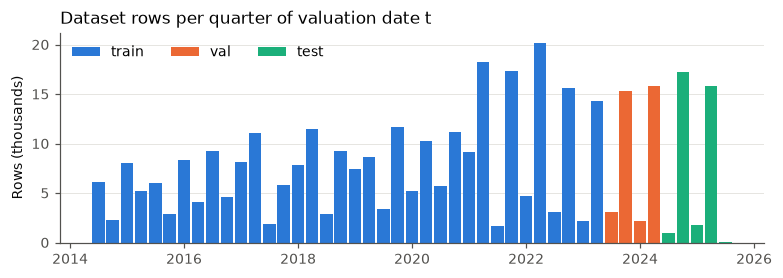

In [8]:
by_split = D.groupby([D["t"].dt.to_period("Q"), "split"]).size().unstack(fill_value=0)[order]
x = by_split.index.to_timestamp()
fig, ax = plt.subplots(figsize=(7.2, 2.6))
for i, s in enumerate(order):
    ax.bar(x, by_split[s] / 1e3, width=80, color=PALETTE[i], label=s)
ax.set_ylabel("Rows (thousands)")
ax.set_title("Dataset rows per quarter of valuation date t", loc="left")
ax.legend(ncols=3, loc="upper left")
fig.tight_layout()
savefig(fig, "fig02_split_timeline")
plt.show()

## 4b. Who are the rows with an unknown club?

About a quarter of all rows have **no known club at *t***. For these players there is no transfer record and no match in the data during the previous year.
- Their league is unknown too, so they **cannot** be part of the 14 core leagues.
- They stay in the dataset with `league_t = "UNKNOWN"` and the flag `club_known = 0`.
- In notebook 03 we report test results with and without them.

The table compares them with known-club rows. Value level and age groups use the fixed bins from `src/config.py`.

In [9]:
from src.config import VALUE_BINS, VALUE_LABELS, AGE_BINS, AGE_LABELS
groups = np.select([D["league_group"].eq("core"), D["club_known"].eq(1)],
                   ["known club: 14 core leagues", "known club: other leagues"], default="unknown club")

def profile(d):
    out = {"rows": len(d), "players": d.player_id.nunique(), "share of all rows (%)": 100 * len(d) / len(D),
           "median value at t (€m)": d.value_t.median() / 1e6}
    vl = pd.cut(d.value_t, VALUE_BINS, labels=VALUE_LABELS, right=False).value_counts(normalize=True).sort_index()
    out |= {f"value {k} (%)": 100 * v for k, v in vl.items()}
    out["median age"] = d.age.median()
    ag = pd.cut(d.age, AGE_BINS, labels=AGE_LABELS, right=False).value_counts(normalize=True).sort_index()
    out |= {f"age {k} (%)": 100 * v for k, v in ag.items()}
    po = d.position.value_counts(normalize=True)
    out |= {f"position {k} (%)": 100 * po.get(k, 0) for k in ["Goalkeeper", "Defender", "Midfield", "Attack"]}
    out["no minutes in last 365 days (%)"] = 100 * (d.minutes_365 == 0).mean()
    out["has a transfer before t (%)"] = 100 * (d.n_transfers_so_far > 0).mean()
    out["median 12-month log change"] = (d.y - d.log_value).median()
    out["12-month value fell (%)"] = 100 * (d.y < d.log_value).mean()
    out |= {f"rows in {s}": int((d.split == s).sum()) for s in ["train", "val", "test"]}
    return pd.Series(out)

names = ["known club: 14 core leagues", "known club: other leagues", "unknown club"]
profiles = [profile(D[groups == g]) for g in names]
unknown_profile = pd.concat(profiles, axis=1, keys=names).reindex(profiles[0].index).round(2)
unknown_profile.to_csv(RESULTS / "table10_unknown_club_profile.csv")
unknown_profile

,known club: 14 core leagues,known club: other leagues,unknown club
rows,136653.00,144841.00,76130.00
players,20288.00,21260.00,14392.00
share of all rows (%),38.21,40.50,21.29
median value at t (€m),1.50,0.40,0.25
value cheap (<€1m) (%),40.10,76.01,89.06
value medium (€1–10m) (%),44.90,23.12,10.83
value expensive (≥€10m) (%),15.01,0.87,0.10
median age,25.72,23.68,25.50
age <21 (%),13.43,24.20,16.71
age 21–25 (%),38.97,44.71,36.78


**Where do unknown-club players play *today*?** This is *descriptive only*. The league column in the valuation file is a 2026 snapshot (section 1), so it says where these players are now, not where they were at *t*. It is never used as a feature.

In [10]:
vfile = pd.read_parquet(PROCESSED / "player_valuations.parquet",
                        columns=["player_id", "date", "player_club_domestic_competition_id"])
vfile = vfile.rename(columns={"date": "t", "player_club_domestic_competition_id": "league_in_2026"})
vfile["t"] = vfile["t"].astype(D["t"].dtype)
u = D.loc[groups == "unknown club", ["player_id", "t"]].merge(vfile, on=["player_id", "t"], how="left")
today_league = (u["league_in_2026"].astype("string").fillna("not in a covered league today")
                .value_counts(normalize=True).mul(100).round(1).head(12).rename("% of unknown-club rows"))
today_league.to_frame()

,% of unknown-club rows
league_in_2026,
IT1,17.6
TR1,9.8
RU1,9.6
L1,8.4
ES1,7.9
GR1,6.1
NL1,5.9
PO1,5.9
FR1,4.6


## 5. Feature list (50 features)

Saved as `results/table05_feature_list.csv` (useful as a table in the paper).

In [11]:
flist = pd.DataFrame([(n, g, d) for n, (g, d) in FEATURE_INFO.items()],
                     columns=["feature", "group", "description"])
flist["type"] = np.where(flist["feature"].isin(CATEGORICAL), "categorical", "numeric")
flist["missing_%"] = (D[FEATURES].isna().mean() * 100).round(1).to_numpy()
flist.to_csv(RESULTS / "table05_feature_list.csv", index=False)
print(flist.groupby("group", sort=False).size().to_string())
with pd.option_context("display.max_colwidth", 80, "display.max_rows", 60):
    display(flist)

group
player            6
value history    11
performance      15
transfers         4
club/league      14


,feature,group,description,type,missing_%
0,age,player,Age in years at t (from date of birth),numeric,0.0
1,height_cm,player,Height in cm (time-invariant),numeric,1.2
2,position,player,Main position: Goalkeeper / Defender / Midfield / Attack,categorical,0.0
3,sub_position,player,"Detailed position, e.g. Centre-Back, Left Winger",categorical,0.1
4,foot,player,Preferred foot,categorical,2.8
5,is_foreign,player,1 if citizenship differs from the country of the league at t,numeric,59.7
6,log_value,value history,log market value at t,numeric,0.0
7,log_value_6m_ago,value history,log value of the last valuation dated 120-270 days before t,numeric,17.9
8,log_value_12m_ago,value history,log value of the last valuation dated 300-450 days before t,numeric,21.4
9,growth_6m,value history,log_value - log_value_6m_ago,numeric,17.9


## 6. Leakage checks

**Check A – source dates.** Every looked-up record must be dated ≤ *t*. This covers the club source, the league source, and the club and league snapshots.

**Check B – "cut the future" test (the strong check).**
1. Delete **every** record dated after a cutoff *C* from all tables (valuations, matches, transfers, games).
2. Rebuild all features from this truncated data.
3. For every row with *t* ≤ *C*, the features must be **exactly the same** as before.

If any feature secretly used future data, its value would change. We run this for two cutoffs.

**Positive control:** a deliberately leaky feature (`career_max_log_value` = the player's highest value over the *whole* history) must **fail** the test. This proves the test can catch leakage.

*Note:* Check B finds leakage that comes from *calculations* over future records. Leakage stored *inside a column* (contract date, caps, valuation club) cannot be found this way. Those columns are excluded based on the evidence in section 1 and notebook 01.

In [12]:
checkA = pd.DataFrame({
    "source": ["club (last transfer / match)", "league (last league match)", "club snapshot", "league snapshot"],
    "rows_checked": [F["club_source_date"].notna().sum(), F["league_source_date"].notna().sum(),
                     F["_club_snap"].notna().sum(), F["_league_snap"].notna().sum()],
    "rows_after_t": [(F["club_source_date"] > F["t"]).sum(), (F["league_source_date"] > F["t"]).sum(),
                     (F["_club_snap"] > F["t"]).sum(), (F["_league_snap"] > F["t"]).sum()],
})
assert checkA["rows_after_t"].sum() == 0
checkA

,source,rows_checked,rows_after_t
0,club (last transfer / match),440036,0
1,league (last league match),239957,0
2,club snapshot,424778,0
3,league snapshot,654662,0


In [13]:
def same(a, b, categorical):
    if categorical:
        return a.astype("string").fillna("<NA>").to_numpy() == b.astype("string").fillna("<NA>").to_numpy()
    return np.isclose(a.astype(float), b.astype(float), rtol=0, atol=1e-9, equal_nan=True)

def leaky_feature(frame):            # positive control: uses the player's WHOLE history
    return frame.groupby("player_id")["log_value_t"].transform("max")

F["career_max_log_value"] = leaky_feature(F)
results = []
for cutoff in ["2019-12-31", "2023-06-30"]:
    Fc = build_features(load_tables(cutoff), verbose=False)
    Fc["career_max_log_value"] = leaky_feature(Fc)
    a = F[F["t"] <= cutoff].set_index(["player_id", "t"]).sort_index()
    b = Fc.set_index(["player_id", "t"]).sort_index()
    assert a.index.equals(b.index), "row sets differ"
    for col in FEATURES + ["career_max_log_value"]:
        ok = same(a[col], b[col], col in CATEGORICAL)
        results.append({"cutoff": cutoff, "feature": col, "rows_compared": len(ok),
                        "rows_changed": int((~ok).sum())})
    del Fc, a, b
checkB = pd.DataFrame(results)
checkB["passed"] = checkB["rows_changed"] == 0
checkB.to_csv(RESULTS / "table06_leakage_cut_future_test.csv", index=False)

real = checkB[checkB.feature != "career_max_log_value"]
ctrl = checkB[checkB.feature == "career_max_log_value"]
print(f"Real features: {real.passed.sum()} / {len(real)} feature×cutoff checks passed")
print("Positive control (leaky on purpose):")
display(ctrl)
assert real["passed"].all() and not ctrl["passed"].any()
F = F.drop(columns="career_max_log_value")

Real features: 100 / 100 feature×cutoff checks passed
Positive control (leaky on purpose):


,cutoff,feature,rows_compared,rows_changed,passed
50,2019-12-31,career_max_log_value,320289,63872,False
101,2023-06-30,career_max_log_value,517195,70694,False


## 7. Save the dataset

- Numbers are stored as `float32`; text columns as `category`.
- Kept columns: IDs, dates, target, split flags, and the 50 features.

In [14]:
keep = (["player_id", "t", "club_t", "league_group", "split", "train_target_before_val",
         "value_t", "target_date", "target_gap_days", "value_target", "y"] + FEATURES)
out = D[keep].copy()
for c in out.columns:
    if c in CATEGORICAL or c in ("league_group", "split"):
        out[c] = out[c].astype("category")
    elif out[c].dtype == "float64":
        out[c] = out[c].astype("float32")
out = out.sort_values(["t", "player_id"]).reset_index(drop=True)
path = PROCESSED / "dataset_v1.parquet"
out.to_parquet(path, compression="zstd", index=False)
print(f"saved {path.name}: {len(out):,} rows × {out.shape[1]} cols, "
      f"{path.stat().st_size / 1e6:.1f} MB on disk, {out.memory_usage(deep=True).sum() / 1e6:.0f} MB in RAM")

saved dataset_v1.parquet: 357,624 rows × 61 cols, 17.5 MB on disk, 85 MB in RAM


## Summary

- One row per (player, valuation date *t*), from July 2014. The target is the log value about 12 months later (± 60 days).
- 50 leak-free features in 5 groups. The "club at *t*" was rebuilt because the valuation club column is leaky.
- The time split has no train/test target overlap, plus an optional embargo flag for tuning.
- Both leakage checks pass, and the positive control is caught.
- Main experiments use the 14 core leagues. The 17 new leagues and the OTHER / UNKNOWN rows serve as extra test sets (decided before any modelling).